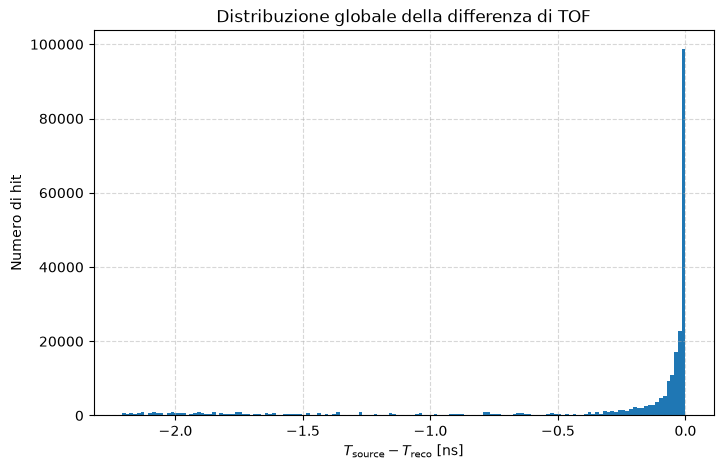

In [1]:
import uproot
import numpy as np
import matplotlib.pyplot as plt

with uproot.open("output2.root") as file:
    tree = file["tof_cal"]
    data = tree.arrays(library="np")

delta = data["delta_ns"]

# delta = delta[np.isfinite(delta)]

plt.figure(figsize=(8, 5))
plt.hist(delta, bins=150)
plt.xlabel(r"$T_{\mathrm{source}}-T_{\mathrm{reco}}$ [ns]")
plt.ylabel("Numero di hit")
plt.title("Distribuzione globale della differenza di TOF")
plt.grid(alpha=0.5, linestyle= '--')
plt.show()

In [2]:
print("Media:", np.mean(delta), "ns")
print("Mediana:", np.median(delta), "ns")
print("Deviazione standard:", np.std(delta), "ns")

Media: -0.3110578997802792 ns
Mediana: -0.03021829401593834 ns
Deviazione standard: 0.5974883167313415 ns


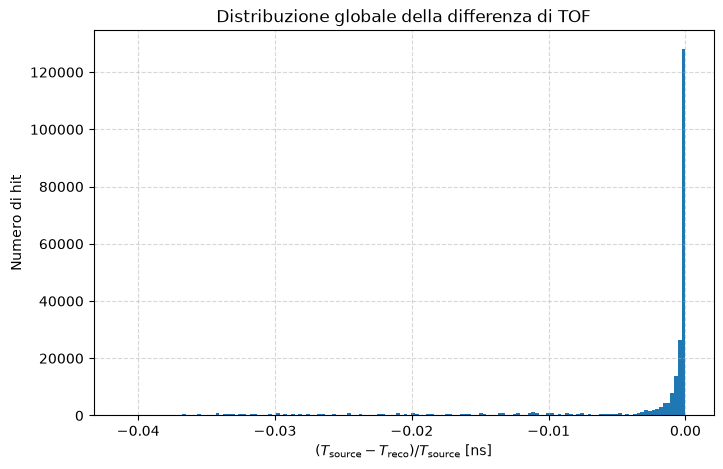

Media: -0.0042881446113654685 ns
Mediana: -0.00023783461457357343 ns
Deviazione standard: 0.009103915853862986 ns


In [3]:
tof_source = data["tof_true"]
delta_rel= delta/tof_source

plt.figure(figsize=(8, 5))
plt.hist(delta_rel, bins=150)
plt.xlabel(r"$(T_{\mathrm{source}}-T_{\mathrm{reco}}) / T_{\mathrm{source}}$ [ns]")
plt.ylabel("Numero di hit")
plt.title("Distribuzione globale della differenza di TOF")
plt.grid(alpha=0.5, linestyle= '--')
plt.show()

print("Media:", np.mean(delta_rel), "ns")
print("Mediana:", np.median(delta_rel), "ns")
print("Deviazione standard:", np.std(delta_rel), "ns")

[3.75197355e-04 3.75197983e-04 3.75197742e-04 ... 2.68739035e-07
 2.68739059e-07 2.68738856e-07]


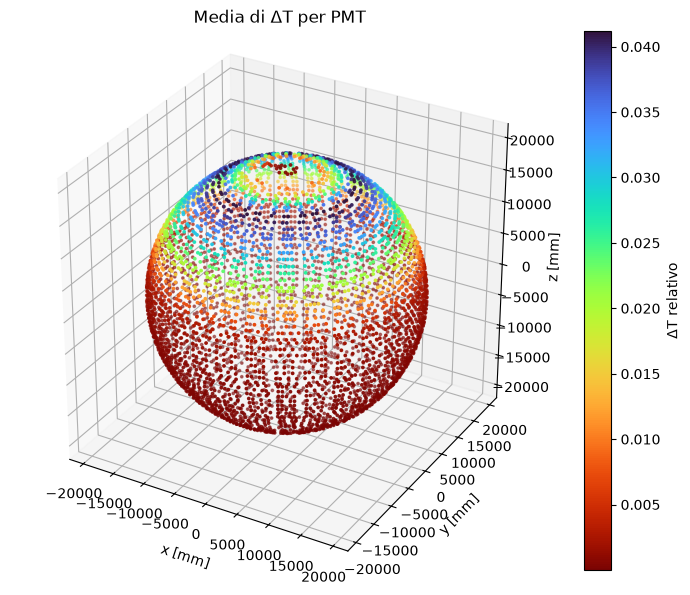

In [4]:
mask = (data["posZ"] ==17300) & data["pmt_type"]
delta = data["delta_ns"]
tof_source = data["tof_true"]
delta_rel= delta/tof_source

pmt_id = data["pmt_id"][mask]
delta_rel = -delta_rel[mask]

print(delta_rel)
x, y, z = np.loadtxt("pmt_positions.csv", usecols = (1, 2, 3), unpack = True)

x= x[pmt_id]
y= y[pmt_id]
z= z[pmt_id]

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

points = ax.scatter(x, y, z,c=delta_rel,cmap='turbo_r', s=3)

ax.set_xlabel("x [mm]")
ax.set_ylabel("y [mm]")
ax.set_zlabel("z [mm]")
ax.set_title("Media di ΔT per PMT")

fig.colorbar(points, ax=ax, label="ΔT relativo")
plt.gca().set_aspect('equal')
plt.show()

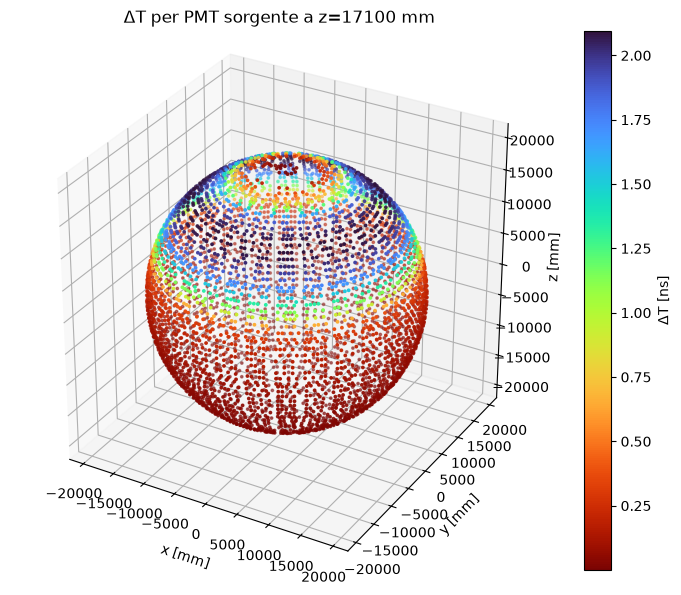

In [5]:
mask = (data["posZ"] ==17100) & data["pmt_type"]
delta = -data["delta_ns"]
tof_source = data["tof_true"]

pmt_id = data["pmt_id"][mask]
delta = delta[mask]

x, y, z = np.loadtxt("pmt_positions.csv", usecols = (1, 2, 3), unpack = True)

x= x[pmt_id]
y= y[pmt_id]
z= z[pmt_id]

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

points = ax.scatter(x, y, z,c=delta,cmap='turbo_r', s=3)

ax.set_xlabel("x [mm]")
ax.set_ylabel("y [mm]")
ax.set_zlabel("z [mm]")
ax.set_title("ΔT per PMT sorgente a z=17100 mm")

fig.colorbar(points, ax=ax, label="ΔT [ns]")
plt.gca().set_aspect('equal')
plt.show()

Text(0.5, 1.0, 'ΔT per un pmt singolo al variare della posizione della sorgente')

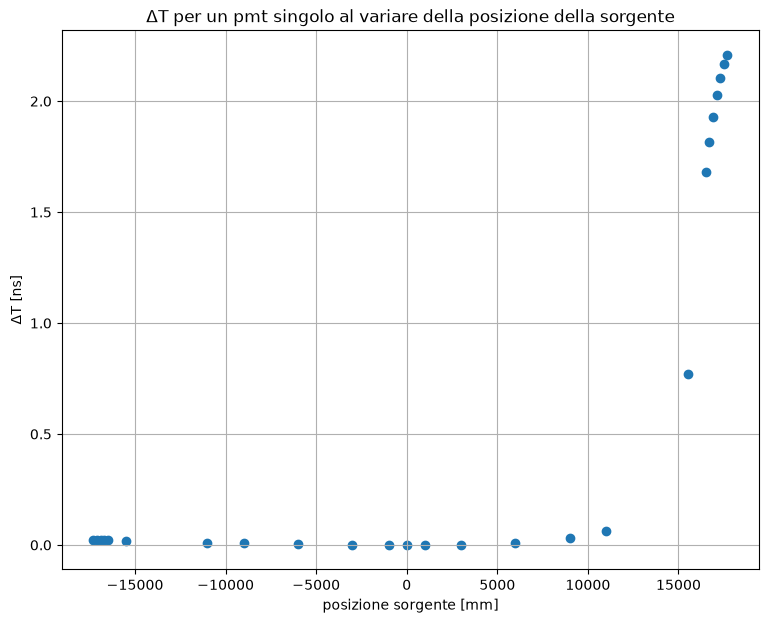

In [11]:
mask = (data["pmt_id"] ==3000)
delta = -data["delta_ns"][mask]
posz = data["posZ"][mask]

fig = plt.figure(figsize=(9, 7))
plt.scatter(posz, delta)

plt.xlabel("posizione sorgente [mm]")
plt.ylabel("ΔT [ns]")
plt.grid()
plt.title("ΔT per un pmt singolo al variare della posizione della sorgente")

Text(0.5, 1.0, 'ΔT per un pmt singolo al variare della posizione della sorgente')

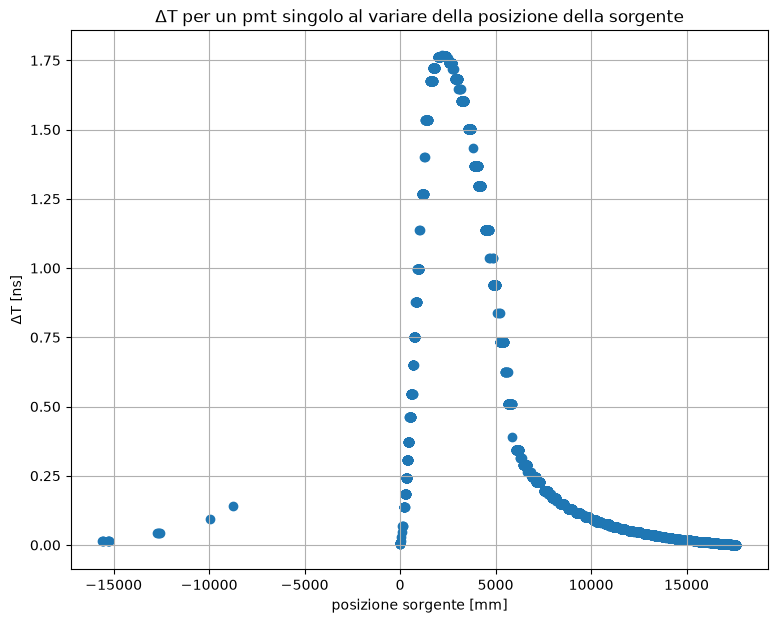

In [12]:
mask = (data["posZ"] ==16500) & (data["pmt_type"])
delta = -data["delta_ns"][mask]
pmtid = data["pmt_id"][mask]

fig = plt.figure(figsize=(9, 7))
plt.scatter(pmtid, delta)

plt.xlabel("posizione sorgente [mm]")
plt.ylabel("ΔT [ns]")
plt.grid()
plt.title("ΔT per un pmt singolo al variare della posizione della sorgente")

4955
4955


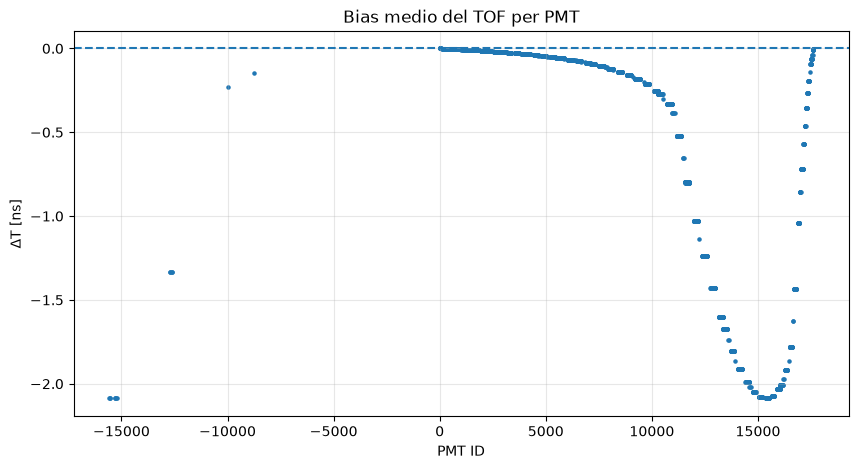

In [13]:
mask = (data["posZ"] ==-17100) & data["pmt_type"]

pmt_id = data["pmt_id"]
delta = data["delta_ns"]
pmt_id= pmt_id[mask]
print(len(pmt_id))
delta = delta[mask]
unique_pmts = np.unique(pmt_id)
print(len(unique_pmts))


plt.figure(figsize=(10, 5))
plt.scatter(pmt_id, delta, s=5)
plt.axhline(0.0, linestyle="--")
plt.xlabel("PMT ID")
plt.ylabel(r"$\Delta$T [ns]")
plt.title("Bias medio del TOF per PMT")
plt.grid(alpha=0.3)
plt.show()

In [5]:
with uproot.open("skim_14451.root") as file:
    tree = file["tofTree"]
    data1 = tree.arrays(library="np")


eventid = data1["evtID"]

int32
17612


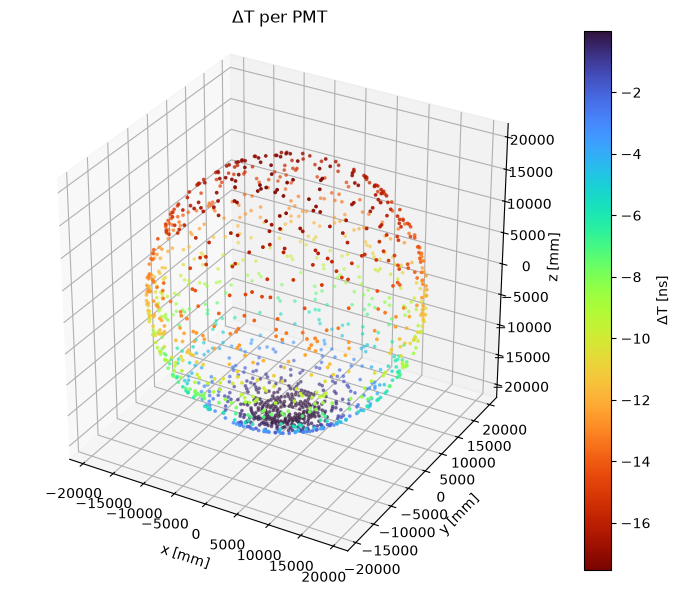

In [6]:
pmtId= data1["pmtid"][eventid==1][0]
print(pmtId.dtype)
mask = (data["posZ"] ==-17100)
delta = data["delta_ns"]

delta= delta[mask]
print(delta.size)
delta= delta[pmtId]

x, y, z = np.loadtxt("pmt_positions.csv", usecols = (1, 2, 3), unpack = True)

x= x[pmtId]
y= y[pmtId]
z= z[pmtId]

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

points = ax.scatter(x, y, z,c=delta,cmap='turbo_r', s=3)

ax.set_xlabel("x [mm]")
ax.set_ylabel("y [mm]")
ax.set_zlabel("z [mm]")
ax.set_title("ΔT per PMT")

fig.colorbar(points, ax=ax, label="ΔT [ns]")
plt.gca().set_aspect('equal')
plt.show()


In [3]:
import numpy as np

x, y, z = np.loadtxt("pmt_positions.csv", usecols=(1, 2,3), unpack = True )

r= np.sqrt(x*x+ y*y + z* z) 

np.savetxt("(i_piedi_della)raggi.txt", r)

print(np.average(r))



19433.93221830236


In [14]:
i = np.loadtxt("pmt_positions.csv", usecols=(0), unpack = True )
for a in i:
    if a<0 :print(a)

-8734.0
-9958.0
-12594.0
-12629.0
-12699.0
-12734.0
-15224.0
-15261.0
-15286.0
-15313.0
-15541.0
-15560.0
-15593.0
